## 1. Inspeção Inicial:
Carregue a base de dados e realize uma exploração inicial. Informe a quantidade de registros, o nome e tipo de dado de cada coluna, e identifique possíveis problemas visíveis na base

In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("dados/clientes.csv", sep=";", encoding="utf-8")

print(df.dtypes)
display(df.head(5))

id_item                    int64
id_pedido                  int64
id_cliente                 int64
idade_cliente              int64
cidade_cliente               str
estado_cliente               str
data_compra                  str
produto                      str
categoria_produto            str
quantidade                 int64
preco_unitario           float64
valor_total              float64
forma_pagamento              str
canal_compra                 str
dispositivo_utilizado        str
status_pedido                str
avaliacao_compra         float64
utilizou_cupom               str
valor_frete              float64
dtype: object


,id_item,id_pedido,id_cliente,idade_cliente,cidade_cliente,estado_cliente,data_compra,produto,categoria_produto,quantidade,preco_unitario,valor_total,forma_pagamento,canal_compra,dispositivo_utilizado,status_pedido,avaliacao_compra,utilizou_cupom,valor_frete
0,1,100001,118,56,Rio de Janeiro,RJ,2021-06-09 00:00:00,Alim_087_Standard,Alimentos,1,133.17,133.17,Boleto,Marketplace,Smartphone,Concluído,3.0,Não,10.47
1,2,100001,118,56,Rio de Janeiro,RJ,2021-06-09 00:00:00,Bele_003_Standard,Beleza,1,38.83,38.83,Boleto,Marketplace,Smartphone,Concluído,3.0,Não,10.47
2,3,100001,118,56,Rio de Janeiro,RJ,2021-06-09 00:00:00,Casa_052_Pro,Casa e Decoração,1,616.33,616.33,Boleto,Marketplace,Smartphone,Concluído,3.0,Não,10.47
3,4,100002,818,29,Aparecida de Goiânia,GO,2022-03-04 00:00:00,Moda_050_Pro,Moda,2,147.06,294.12,Cartão de Crédito,Marketplace,Desktop,Concluído,5.0,Não,19.16
4,5,100003,468,25,Feira de Santana,BA,2022-04-10 00:00:00,Bele_102_Standard,Beleza,1,147.45,147.45,Cartão de Crédito,App Mobile,Tablet,Concluído,6.0,Sim,0.39


In [112]:
# len() conta quantas linhas (registros) a base tem
print(f"Registros: {len(df)}")
# len() em df.columns conta quantas colunas a base tem
print(f"Colunas: {len(df.columns)}\n")
# df.info()

# Valores ausentes por coluna
print(df.isna().sum())

# Estatísticas das colunas numéricas (procure mínimos e máximos estranhos)
print(df.describe())

# Quantidade de linhas com quantidade zero ou negativa
print(f"\nQuantidade de linhas com vlaor negativo ou zero: {(df["quantidade"] <= 0).sum()}")

# Linhas duplicadas e id_item repetido
print("Linhas duplicadas:", df.duplicated().sum())
print("id_item repetido:", df["id_item"].duplicated().sum())

Registros: 50000
Colunas: 19

id_item                      0
id_pedido                    0
id_cliente                   0
idade_cliente                0
cidade_cliente             150
estado_cliente             150
data_compra                  0
produto                      0
categoria_produto            0
quantidade                   0
preco_unitario               0
valor_total                  0
forma_pagamento              0
canal_compra                 0
dispositivo_utilizado        0
status_pedido                0
avaliacao_compra         14290
utilizou_cupom               0
valor_frete                  0
dtype: int64
            id_item      id_pedido   id_cliente  idade_cliente    quantidade  \
count  50000.000000   50000.000000  50000.00000   50000.000000  50000.000000   
mean   24927.515980  114836.055940    958.05788      40.996340      1.633300   
std    14389.854334    8590.258804   1170.56679      38.291075      1.471392   
min        1.000000  100001.000000      1.00000 

## 2. Tratamento de Inconsistências:
Identifique e trate valores ausentes, registros duplicados e quaisquer erros lógicos ou de digitação encontrados. Documente passo a passo as regras de limpeza aplicadas.

In [113]:
df_limpo = pd.read_csv("dados/clientes.csv", sep=";", encoding="utf-8")

print("Linhas antes da limpeza:", len(df_limpo))

Linhas antes da limpeza: 50000


In [114]:
# Remove linhas totalmente repetidas (mesmo registro aparecendo duas vezes)
df_limpo = df_limpo.drop_duplicates()
print("Linhas após remover duplicatas:", len(df_limpo))

Linhas após remover duplicatas: 49850


In [115]:
# Corrigindo colunas com nomes fixos e iguais ("Casa Decoracao" para "Casa e Decoração") * .replace faz isso
df_limpo["categoria_produto"] = df_limpo["categoria_produto"].replace(
    {"Casa Decoracao": "Casa e Decoração", "Eletronicos": "Eletrônicos"})

# Corrige a forma de pagamento escrita errado
df_limpo["forma_pagamento"] = df_limpo["forma_pagamento"].replace(
    {"Cartao Credito": "Cartão de Crédito"})

In [116]:
# Conta quantas linhas têm quantidade zero ou negativa (não existe comprar -10 unidades)
print("Quantidade inválida:", (df_limpo["quantidade"] <= 0).sum())

# Mantém só as linhas com quantidade maior que zero
# reset_index refaz a numeração das linhas (0, 1, 2...) depois de remover algumas
df_limpo = df_limpo[df_limpo["quantidade"] > 0].reset_index(drop=True)
print("Linhas após remover quantidade inválida:", len(df_limpo))

Quantidade inválida: 82
Linhas após remover quantidade inválida: 49768


In [117]:
# Converte texto para data; as datas inválidas viram NaT (data nula)
df_limpo["data_compra"] = pd.to_datetime(df_limpo["data_compra"], errors="coerce")
print("Datas inválidas:", df_limpo["data_compra"].isna().sum())

# Todos os itens de um pedido têm a mesma data, então copia a data de outro item do mesmo pedido
df_limpo["data_compra"] = df_limpo["data_compra"].fillna(
    df_limpo.groupby("id_pedido")["data_compra"].transform("first"))
print("Datas ainda nulas:", df_limpo["data_compra"].isna().sum())

Datas inválidas: 149
Datas ainda nulas: 43


In [118]:
# Contando quantas idades tem mais de 100 anos
print("Idades inválidas:", (df_limpo["idade_cliente"] > 100).sum())

# Mantém só idades até 100; o resto vira nulo
df_limpo["idade_cliente"] = df_limpo["idade_cliente"].where(df_limpo["idade_cliente"] <= 100)

# A idade é do cliente, então copiei de outra compra do mesmo cliente e colei na que estava vazia
df_limpo["idade_cliente"] = df_limpo["idade_cliente"].fillna(
    df_limpo.groupby("id_cliente")["idade_cliente"].transform("first"))

Idades inválidas: 68


In [119]:
# Cidade e estado também são do cliente: copia de outra compra dele
# O que não der para recuperar vira "Não informado"
for linha in ["cidade_cliente", "estado_cliente"]:
    df_limpo[linha] = df_limpo[linha].fillna(df_limpo.groupby("id_cliente")[linha].transform("first"))
    df_limpo[linha] = df_limpo[linha].fillna("Não informado")

In [120]:
print("Notas inválidas:", (df_limpo["avaliacao_compra"] > 5).sum() + (df_limpo["avaliacao_compra"] < 1).sum())

df_limpo["avaliacao_compra"] = df_limpo["avaliacao_compra"].where(df_limpo["avaliacao_compra"] <= 5)
df_limpo["avaliacao_compra"] = df_limpo["avaliacao_compra"].where(df_limpo["avaliacao_compra"] >= 1)

Notas inválidas: 150


In [121]:
print("Linhas depois da limpeza:", len(df_limpo))
print(df_limpo.isna().sum())
print("Quantidade mínima:", df_limpo["quantidade"].min())
print("Idade máxima:", df_limpo["idade_cliente"].max())

df_limpo.to_csv("dados/clientes_limpo.csv", sep=";", index=False, encoding="utf-8")

Linhas depois da limpeza: 49768
id_item                      0
id_pedido                    0
id_cliente                   0
idade_cliente                1
cidade_cliente               0
estado_cliente               0
data_compra                 43
produto                      0
categoria_produto            0
quantidade                   0
preco_unitario               0
valor_total                  0
forma_pagamento              0
canal_compra                 0
dispositivo_utilizado        0
status_pedido                0
avaliacao_compra         14409
utilizou_cupom               0
valor_frete                  0
dtype: int64
Quantidade mínima: 1
Idade máxima: 80.0


## 3. Demografia de Clientes:
Quantos clientes distintos realizaram compras na loja? Analise e apresente a distribuição desses clientes pelas cidades e estados presentes na base.

In [122]:
# nunique() conta valores distintos: cada cliente é contado uma vez só
# print(df_limpo.columns)
print("Clientes distintos:", df_limpo["id_cliente"].nunique())

# Uma linha por cliente, para não contar o mesmo cliente várias vezes (uma por compra)
clientes = df_limpo.drop_duplicates("id_cliente")

Clientes distintos: 3533


In [123]:
# Distribuição por estado
por_estado = clientes["estado_cliente"].value_counts()
print(por_estado)

# Distribuição por cidade (10 maiores)
por_cidade = clientes["cidade_cliente"].value_counts()
print(por_cidade.head(10))

estado_cliente
RJ               373
PE               371
GO               362
BA               360
MG               357
CE               347
PR               344
RS               341
SP               338
SC               338
Não informado      2
Name: count, dtype: int64
cidade_cliente
Feira de Santana        135
Aparecida de Goiânia    129
Fortaleza               123
Juazeiro do Norte       119
Anápolis                117
Salvador                116
Goiânia                 116
Vitória da Conquista    109
Caucaia                 105
Pelotas                 102
Name: count, dtype: int64


A loja atendeu 3.533 clientes distintos:

Cada um dos 10 estados tem entre 338 e 373 clientes, com RJ (373), PE (371) e GO (362) no topo.

Por cidade, Feira de Santana (135), Aparecida de Goiânia (129) e Fortaleza (123), mas a diferença entre as outras cidades é pequena.

Apenas 2 clientes ficaram sem localização.

## 4. Ticket Médio:
Calcule o ticket médio da loja. Lembre-se de considerar apenas pedidos com status de "Concluído" e calcular a média sobre pedidos distintos, não sobre itens individuais

In [124]:
# Valor de cada item = quantidade x preço
df_limpo["valor_item"] = df_limpo["quantidade"] * df_limpo["preco_unitario"]

# Só pedidos concluídos
concluidos = df_limpo[df_limpo["status_pedido"] == "Concluído"]

# Soma os itens de cada pedido: agora temos uma linha por pedido
valor_por_pedido = concluidos.groupby("id_pedido")["valor_item"].sum()

# Ticket médio = média do valor por pedido
# Usando .round para arredondar os resultados
print("Pedidos concluídos:", len(valor_por_pedido))
print("Faturamento total:", valor_por_pedido.sum().round(2))
print("Ticket médio:", valor_por_pedido.mean().round(2))

Pedidos concluídos: 14584
Faturamento total: 22828748.6
Ticket médio: 1565.33


Considerando apenas pedidos concluídos e contando pedidos distintos, a loja teve 14.584 pedidos que geraram ( RS 22.828.748,60 ) de faturamento.

O ticket médio é de R$ 1.565,33 por pedido. Esse valor serve de referência para ações como frete grátis ou desconto acima do ticket médio, para estimular carrinhos maiores.

## 5. Curva de Produtos:
Quais foram os 10 produtos e as 5 categorias de produtos mais comprados em toda a história da loja? Considere a quantidade de unidades comercializadas.

In [125]:
# Retirando pedidos cancelados porque não foram realmente comprados
vendidos = df_limpo[df_limpo["status_pedido"] != "Cancelado"]

# Soma as unidades vendidas de cada produto e pega os 10 maiores
top_produtos = vendidos.groupby("produto")["quantidade"].sum().sort_values(ascending=False).head(10)
print(top_produtos)

# Mesma lógica para as 5 categorias
top_categorias = vendidos.groupby("categoria_produto")["quantidade"].sum().sort_values(ascending=False).head(5)
print(top_categorias)

produto
Livr_117_Pro         702
Alim_017_Basic       685
Alim_063_Premium     670
Alim_057_Basic       666
Moda_046_Standard    663
Bele_092_Pro         658
Casa_104_Pro         656
Casa_090_Premium     652
Alim_110_Standard    648
Casa_029_Basic       648
Name: quantidade, dtype: int64
categoria_produto
Casa e Decoração    12244
Livros              11481
Eletrônicos          8902
Brinquedos           8775
Alimentos            8194
Name: quantidade, dtype: int64


Pedidos cancelados foram desconsiderados, pois não representam unidades de contabilização.

Entre os produtos, lideram Livr_117_Pro (702 unidades), Alim_017_Basic (685) e Alim_063_Premium (670), mas a diferença entre o 1º e o 10º é pequena (702 contra 648), o que mostra que nenhum produto teve uma venda absurda.

Entre as categorias, Casa e Decoração vence com 12.244 unidades, seguida de Livros (11.481), Eletrônicos (8.902), Brinquedos (8.775) e Alimentos (8.194).

Casa e Decoração e Livros teve maior volume, com esse valor é um bom numero para comparações.

## 6. Top Clientes (VIPs):
Identifique os 10 clientes que mais gastaram financeiramente na loja. Para este cálculo, considere o total financeiro de pedidos distintos e concluídos por cliente.

In [126]:
# Valor de cada item = quantidade x preço
df_limpo["valor_item"] = df_limpo["quantidade"] * df_limpo["preco_unitario"]

concluidos = df_limpo[df_limpo["status_pedido"] == "Concluído"]

# Soma o valor dos pedidos concluídos de cada cliente e pega os 10 maiores
top_clientes = concluidos.groupby("id_cliente")["valor_item"].sum().sort_values(ascending=False).head(10)
print(top_clientes.round(2))

id_cliente
72     100413.03
202     92522.30
897     75130.69
980     75033.47
442     73107.39
725     72750.86
602     68999.82
447     66933.68
782     65965.26
875     64820.40
Name: valor_item, dtype: float64


Considerando apenas pedidos concluídos, o cliente que mais gastou foi o ID 72 (RS 100.413,03), seguido do ID 202 (RS 92.522,30) e do ID 897 (RS 75.130,69).

Os 10 clientes VIPs somam R$ 755.676,90, cerca de 3,3% do faturamento total, o que mostra que a receita é bem distribuída e não depende de poucos clientes.

## 7. Sazonalidade e Evolução:
Analise a linha do tempo das vendas agrupando por meses. Identifique e explique quais períodos históricos apresentaram picos de maior atividade comercial

In [127]:
vendas = df_limpo[df_limpo["status_pedido"] != "Cancelado"].copy()

# Colunas de ano e mês (apos a conversao para pd.to_datetime, utilizei .dt. para pegar so o ANO e o MES da data
vendas["ano"] = vendas["data_compra"].dt.year # 2021, 2022, 2023
vendas["mes"] = vendas["data_compra"].dt.month # 1 A 12

# Soma do faturamento por ano e mês
por_mes = vendas.groupby(["ano", "mes"])["valor_total"].sum()
print(f"Faturamento de todos os meses e anos\n {por_mes.round(2)}")

print(f"\nOs 5 maiores faturamentos por mes\n {por_mes.sort_values(ascending=False).head(5).round(2)}")

Faturamento de todos os meses e anos
 ano     mes 
2021.0  1.0     1032385.68
        2.0      823701.65
        3.0     1041267.05
        4.0      828854.42
        5.0      921419.24
        6.0      940609.35
        7.0     1018305.48
        8.0      992060.40
        9.0      821777.51
        10.0     851259.50
        11.0     976010.60
        12.0    1076800.90
2022.0  1.0     1035489.96
        2.0      916444.18
        3.0      937031.99
        4.0      879974.88
        5.0      924187.41
        6.0     1032187.81
        7.0      847077.40
        8.0      960805.80
        9.0     1068814.66
        10.0     845276.82
        11.0     996281.56
        12.0     945676.59
2023.0  1.0     1036820.25
        2.0      865381.24
        3.0      912428.73
        4.0      923858.47
        5.0      932019.50
        6.0      924406.75
        7.0      989382.17
        8.0      978891.73
        9.0     1055930.31
        10.0     964722.04
        11.0    1011096.07
    

In [128]:
# Agrupando o faturamento por mes em cada ano da base
faturamento_2021 = vendas[vendas["ano"] == 2021].groupby("mes")["valor_total"].sum()
faturamento_2022 = vendas[vendas["ano"] == 2022].groupby("mes")["valor_total"].sum()
faturamento_2023 = vendas[vendas["ano"] == 2023].groupby("mes")["valor_total"].sum()

# juntando os 3 faturamento em uma tabela
tabela = pd.DataFrame({"2021": faturamento_2021, "2022": faturamento_2022, "2023": faturamento_2023})
print(f"Faturamento dos anos (2021, 2022, 2023)\n {tabela.round(0)}")

Faturamento dos anos (2021, 2022, 2023)
            2021       2022       2023
mes                                  
1.0   1032386.0  1035490.0  1036820.0
2.0    823702.0   916444.0   865381.0
3.0   1041267.0   937032.0   912429.0
4.0    828854.0   879975.0   923858.0
5.0    921419.0   924187.0   932020.0
6.0    940609.0  1032188.0   924407.0
7.0   1018305.0   847077.0   989382.0
8.0    992060.0   960806.0   978892.0
9.0    821778.0  1068815.0  1055930.0
10.0   851260.0   845277.0   964722.0
11.0   976011.0   996282.0  1011096.0
12.0  1076801.0   945677.0  1294078.0


In [129]:
pedidos = vendas.groupby(["ano", "mes"])["id_pedido"].nunique()
print(f"{pedidos.sort_values(ascending=False).head(5)}")

ano     mes 
2023.0  12.0    719
2021.0  12.0    682
2023.0  5.0     646
2021.0  8.0     643
2022.0  11.0    638
Name: id_pedido, dtype: int64


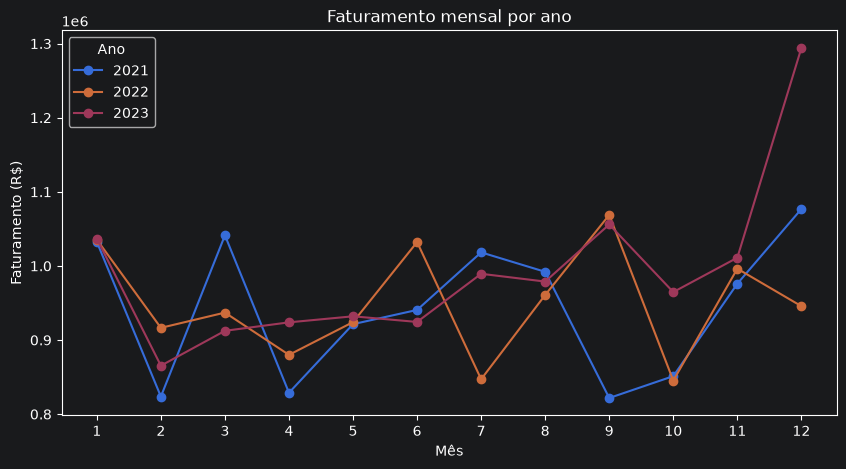

In [130]:
tabela.plot(marker="o", figsize=(10, 5))
plt.title("Faturamento mensal por ano")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.xticks(range(1, 13))
plt.legend(title="Ano")
plt.show()

O faturamento é estável, com cerca de RS 11,3 milhões em 2021 e 2022 e RS 11,9 milhões em 2023.

Os picos foram dezembro de 2023 (R$ 1,29 milhão e 719 pedidos), dezembro de 2021, setembro de 2022 e 2023 e janeiro de 2023.

Janeiro é o que teve a sazonalidade mantendo os numeros altos, ja fevereiro foi fraco, o que indica sazonalidade moderada ligada as festas de fim de ano.

A loja deve reforçar estoque e campanhas em dezembro e janeiro.

## 8. Canais e Pagamentos:
Compare o volume financeiro gerado pelas diferentes formas de pagamento e pelos canais de compra (ex: App, Site). Quais métodos dominam a preferência do consumidor?

In [131]:
# Faturamento por forma de pagamento (pedidos concluídos)
pagamento = concluidos.groupby("forma_pagamento")["valor_item"].sum().sort_values(ascending=False)
print(pagamento.round(2))

# Faturamento por canal de compra
canal = concluidos.groupby("canal_compra")["valor_item"].sum().sort_values(ascending=False)
print(canal.round(2))

forma_pagamento
Cartão de Crédito    9845143.95
PIX                  7021721.44
Boleto               3267149.23
Carteira Digital     1416139.99
Cartão de Débito     1278593.99
Name: valor_item, dtype: float64
canal_compra
App Mobile     13853785.48
Site Web        6751212.34
Marketplace     2223750.78
Name: valor_item, dtype: float64


Considerando pedidos concluídos, o Cartão de Crédito foi o método mais utilizado pelos consumidores, com RS 9,85 milhões, seguido do PIX (RS 7,02 milhões) e do Boleto.

Ja a Carteira Digital e Cartão de Débito com a menor quantidade. Por canal, o App Mobile lidera com RS 13,85 milhões, contra Site Web e Marketplace.

O consumidor prefere comprar pelo celular e pagar com crédito ou PIX, então promoções, cashback e parcelamento devem ser focados nesses meios. (meios mais práticos)

## 9. Taxa de Insucesso:
Investigue os pedidos classificados como "Cancelados" e "Devolvidos". Qual a participação percentual desses status no total de pedidos distintos realizados na loja? Existe alguma categoria de produto que sofra mais devoluções?

In [132]:
print(df_limpo["status_pedido"].value_counts())

status_pedido
Concluído        28429
Em Transporte     7185
Cancelado         7114
Devolvido         7040
Name: count, dtype: int64


In [133]:
# Uma linha por pedido (drop_duplicates remove os itens repetidos do mesmo pedido)
pedidos = df_limpo.drop_duplicates("id_pedido")
total_pedidos = len(pedidos)

# Quantidade de pedidos em cada status e percentual sobre o total
pedidos_status = pedidos["status_pedido"].value_counts()
print("Total de pedidos:", total_pedidos)
print(pedidos_status)
print((pedidos_status / total_pedidos * 100).round(2))

Total de pedidos: 25406
status_pedido
Concluído        14584
Em Transporte     3679
Devolvido         3594
Cancelado         3549
Name: count, dtype: int64
status_pedido
Concluído        57.40
Em Transporte    14.48
Devolvido        14.15
Cancelado        13.97
Name: count, dtype: float64


In [134]:
# Uma linha por pedido em cada categoria (um pedido pode ter itens de categorias diferentes)
pedidos_categorias = df_limpo.drop_duplicates(["id_pedido", "categoria_produto"])

# Total de pedidos de cada categoria
total_categorias = pedidos_categorias["categoria_produto"].value_counts()

# Pedidos devolvidos de cada categoria
devolvidos = pedidos_categorias[pedidos_categorias["status_pedido"] == "Devolvido"]
devolvidos_categorias = devolvidos["categoria_produto"].value_counts()

# Taxa de devolução = devolvidos / total da categoria
taxa_devolucao = (devolvidos_categorias / total_categorias * 100).sort_values(ascending=False)
print(devolvidos_categorias)
print(taxa_devolucao.round(2))

categoria_produto
Casa e Decoração    1077
Livros              1019
Brinquedos           833
Eletrônicos          801
Alimentos            715
Beleza               683
Esportes             633
Moda                 543
Name: count, dtype: int64
categoria_produto
Brinquedos          15.06
Casa e Decoração    14.29
Livros              14.15
Eletrônicos         14.14
Esportes            13.89
Beleza              13.85
Moda                13.83
Alimentos           13.73
Name: count, dtype: float64


Dos 25.406 pedidos distintos, 57,40% foram concluídos, 13,97% cancelados, 14,15% devolvidos e 14,48% ainda estão em transporte.

Somando cancelamentos e devoluções, 28,12% dos pedidos não geraram receita, quase 3 em cada 10, o que é uma perda relevante.

Entre as categorias, a taxa de devolução vai de 13,73% (Alimentos) a 15,06% (Brinquedos), perto da média geral de 14,15%.

Como a diferença é pequena, nenhuma categoria se destaca, e o problema parece ser geral da operação e não de um tipo de produto.

Como a base não informa o motivo das devoluções.

## 10. Representação Gráfica:
Construa pelo menos 4 (quatro) gráficos relevantes que complementem as análises anteriores. Abaixo de cada visualização, escreva uma legenda analítica
explicando o que os dados mostram.


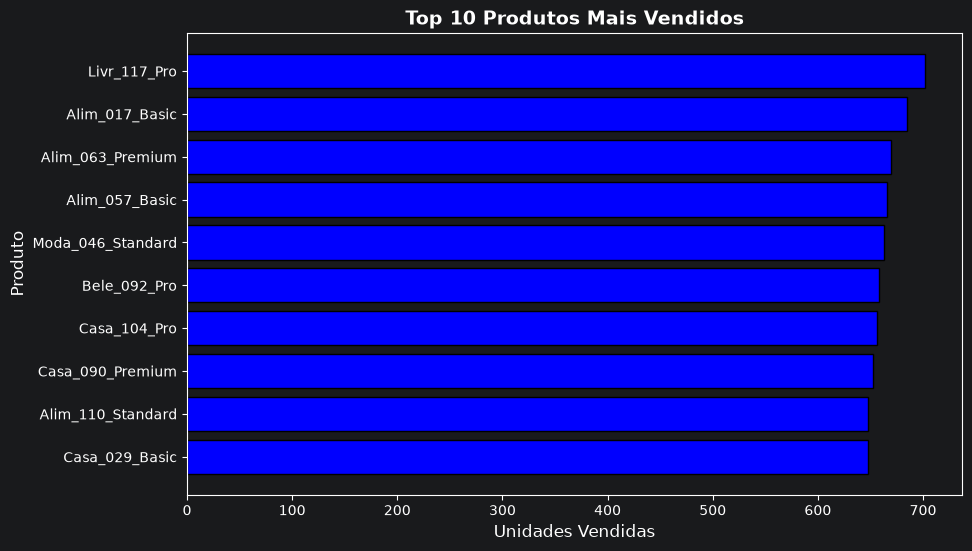

In [140]:
plt.figure(figsize=(10, 6))

# sort_values() deixa o maior produto no topo do gráfico
top = top_produtos.sort_values()
plt.barh(top.index, top, color='blue', edgecolor='black')

plt.title('Top 10 Produtos Mais Vendidos', fontsize=14, fontweight='bold')
plt.xlabel('Unidades Vendidas', fontsize=12)
plt.ylabel('Produto', fontsize=12)

plt.show()

As vendas dos 10 produtos são muito parecidas: o líder, Livr_117_Pro (702 unidades), vende só 8% a mais que o 10º colocado (648). Nenhum produto domina, então o catálogo é equilibrado e as campanhas podem ser distribuídas.

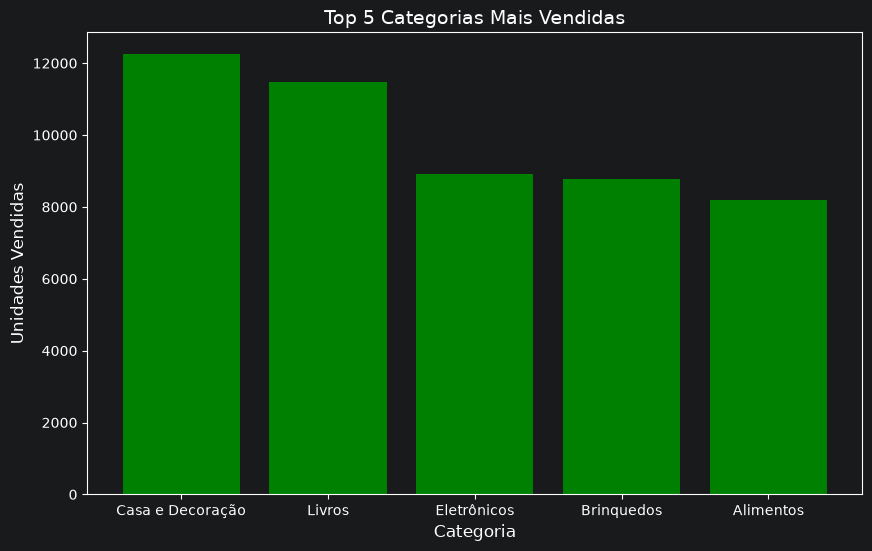

In [141]:
plt.figure(figsize=(10, 6))

plt.bar(top_categorias.index, top_categorias, color='green')

plt.title('Top 5 Categorias Mais Vendidas', fontsize=14)
plt.xlabel('Categoria', fontsize=12)
plt.ylabel('Unidades Vendidas', fontsize=12)

plt.show()

Casa e Decoração (12.244) e Livros (11.481) vendem bem mais que Eletrônicos, Brinquedos e Alimentos, que ficam entre 8.194 e 8.902 unidades. São as categorias com maior potencial para campanhas e vendas cruzadas.

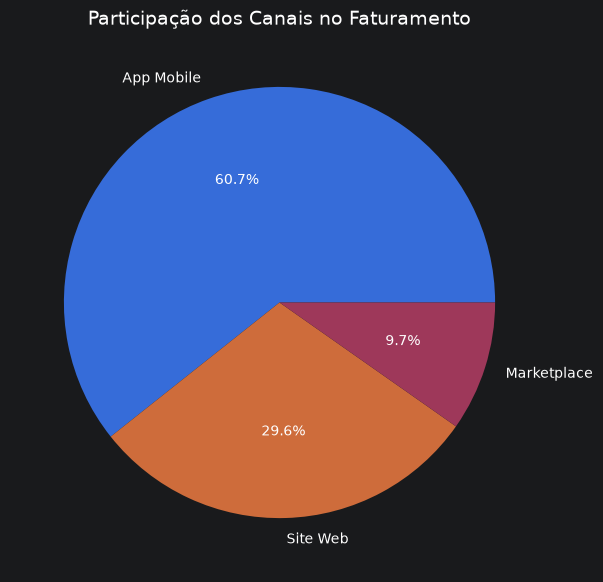

In [142]:
plt.figure(figsize=(7, 7))

# labels = nomes dos canais; autopct mostra o percentual em cada fatia
plt.pie(canal, labels=canal.index, autopct="%1.1f%%")

plt.title('Participação dos Canais no Faturamento', fontsize=14)

plt.show()

O App Mobile gera 60,7% do faturamento, contra 29,6% do Site Web e 9,7% do Marketplace. O consumidor prefere comprar pelo celular, então o app deve ser prioridade em campanhas e melhorias.

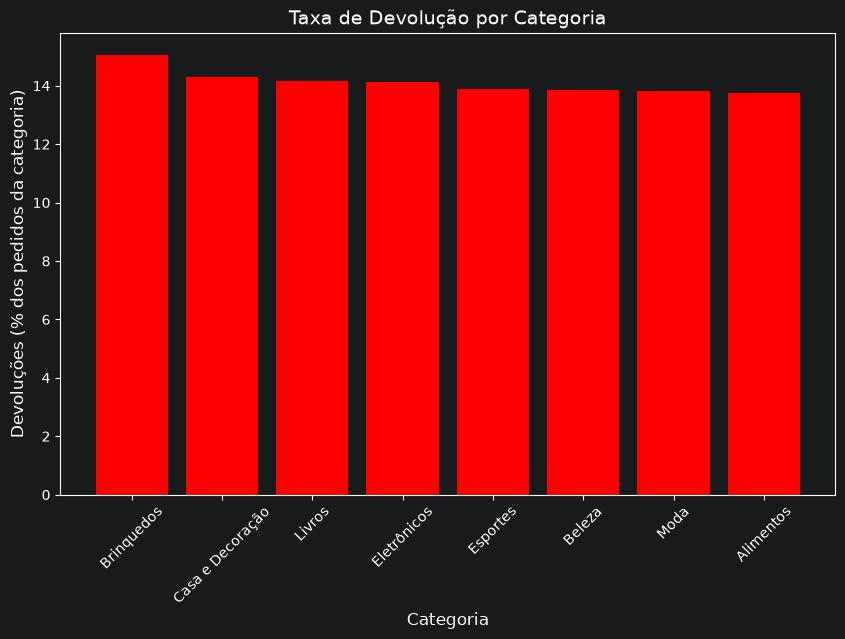

In [143]:
plt.figure(figsize=(10, 6))

plt.bar(taxa_devolucao.index, taxa_devolucao, color='red')

plt.title('Taxa de Devolução por Categoria', fontsize=14)
plt.xlabel('Categoria', fontsize=12)
plt.ylabel('Devoluções (% dos pedidos da categoria)', fontsize=12)
plt.xticks(rotation=45)  # inclina os nomes para não ficarem sobrepostos

plt.show()

As três linhas seguem um padrão parecido: janeiro alto e fevereiro baixo em todos os anos. O maior pico é dezembro de 2023 (RS 1,29 milhão), que se afasta das demais. O faturamento é estável, em torno de RS 950 mil por mês.

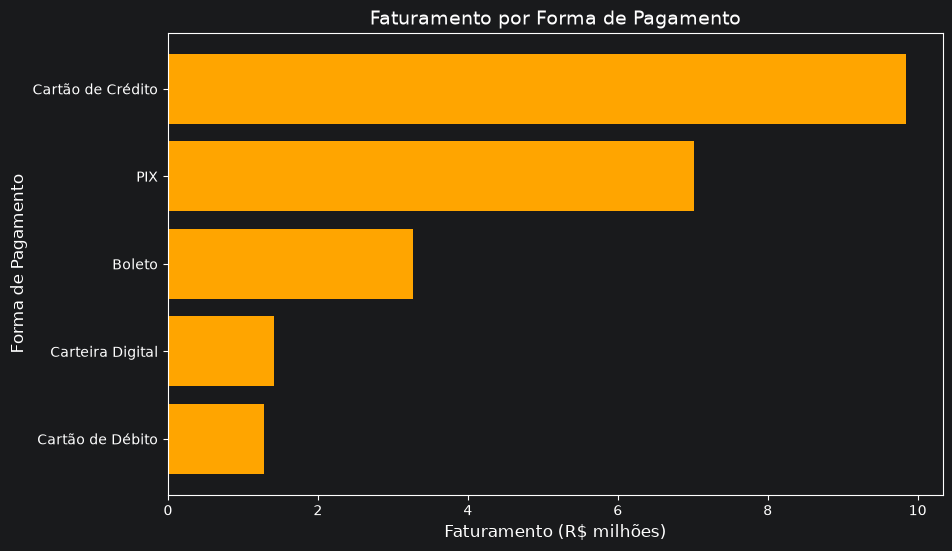

In [144]:
plt.figure(figsize=(10, 6))

# divide por 1 milhão para o eixo ficar em "R$ milhões"; sort_values deixa o maior no topo
pag = (pagamento / 1000000).sort_values()
plt.barh(pag.index, pag, color='orange')

plt.title('Faturamento por Forma de Pagamento', fontsize=14)
plt.xlabel('Faturamento (R$ milhões)', fontsize=12)
plt.ylabel('Forma de Pagamento', fontsize=12)

plt.show()

O Cartão de Crédito (RS 9,85 mi, 43,1%) e o PIX (RS 7,02 mi, 30,8%) somam quase 74% do faturamento. Boleto (14,3%), Carteira Digital (6,2%) e Cartão de Débito (5,6%) têm peso pequeno, então promoções de pagamento devem focar em crédito e PIX.